# Joined feature exploration

In this notebook I join the manager-level and match-level training data to build early clan-vs-clan feature ideas. I aggregate the six managers in each clan into clan summaries, merge those summaries onto both sides of each matchup, and create directional differences such as `clan_1_feature - clan_2_feature`.

The goal is exploratory: check which activity, training, quality, multiplier, payer, weak-link, and balance features appear related to match outcomes and point margins. These findings are used to guide the final feature engineering in the classifier notebook, not as causal proof.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 300)
pd.set_option("display.max_rows", 200)

PROJECT_ROOT = Path("../..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TRAIN_DATA_PATH = PROJECT_ROOT / "data" / "train"

members = pd.read_csv(TRAIN_DATA_PATH / "member_stats_training.csv")
matches = pd.read_csv(TRAIN_DATA_PATH / "clan_matches_training.csv")


print("members shape:", members.shape)
print("matches shape:", matches.shape)

display(members.head())
display(matches.head())

members shape: (291456, 15)
matches shape: (24288, 5)


,clan_id,user_id,days_active_last_28_days,days_active_last_7_days,days_since_last_active,registration_country,registration_platform_specific,cohort_day,training_count_last_28_days,is_payer_lifetime,dynamic_payment_segment,clan_multiplier,avg_stars_top_11_players,avg_stars_top_3_players,avg_training_bonus
0,clan_1,user_1,28,7,0,Israel,Android Phone,1721,159,True,4) Whale,3,8.219321,9.440622,15.5
1,clan_2,user_2,27,7,0,Malaysia,Android Phone,2923,214,True,4) Whale,2,8.931697,9.882221,15.5
2,clan_3,user_3,28,7,0,Poland,Android Phone,219,2930,True,4) Whale,3,8.545721,8.980044,17.0
3,clan_4,user_4,28,7,0,Germany,iOS Phone,47,57,True,4) Whale,3,7.895794,8.737822,15.5
4,clan_5,user_5,28,7,0,France,Android Phone,1181,4179,True,4) Whale,4,8.170182,9.144755,16.5


,clan_1_id,clan_2_id,clan_1_points,clan_2_points,clan_winner
0,clan_7201,clan_25726,0,72,2
1,clan_5202,clan_16269,0,78,2
2,clan_26609,clan_2868,0,84,2
3,clan_5093,clan_37398,0,84,2
4,clan_19283,clan_42497,0,90,2


In [3]:
members = members.copy()
matches = matches.copy()


members["is_payer_lifetime_num"] = (
    members["is_payer_lifetime"]
    .astype(str)
    .str.lower()
    .map({"true": 1, "false": 0})
)

# tiny anomaly handling from notebook 02
members["avg_stars_top_11_players"] = members["avg_stars_top_11_players"].clip(lower=0)

## First clan-level feature set

As an initial feature set, I aggregate the six managers in each clan into simple clan summaries. These features are meant to capture activity, recency, training behavior, squad quality, multiplier strength, and payer composition at the clan level.

In [4]:
agg_spec = {
    "days_active_last_7_days": ["mean", "min"],
    "days_since_last_active": ["mean", "max"],
    "training_count_last_28_days": ["mean"],
    "clan_multiplier": ["sum"],
    "avg_stars_top_11_players": ["mean", "std"],
    "avg_training_bonus": ["mean", "min", "std"],
    "is_payer_lifetime_num": ["sum"],
}

agg_spec

{'days_active_last_7_days': ['mean', 'min'],
 'days_since_last_active': ['mean', 'max'],
 'training_count_last_28_days': ['mean'],
 'clan_multiplier': ['sum'],
 'avg_stars_top_11_players': ['mean', 'std'],
 'avg_training_bonus': ['mean', 'min', 'std'],
 'is_payer_lifetime_num': ['sum']}

## Additional clan profile features

I also add a few hand-built clan profile features that are not captured well by simple means. These include lower-half squad quality, inactivity share, recent activity share, and payer-segment composition. The purpose is to test whether weak links or concentrated roster patterns matter for match outcomes.

In [5]:
clan_features = members.groupby("clan_id").agg(agg_spec)

clan_features.columns = [
    f"{col}_{stat}" for col, stat in clan_features.columns
]

clan_features = clan_features.reset_index()

extra_clan_features = members.groupby("clan_id").agg(
    bottom2_stars_top11_mean=("avg_stars_top_11_players", lambda x: np.sort(x)[:2].mean()),
    inactive_7plus_share=("days_since_last_active", lambda x: np.mean(x >= 7)),
    recently_active_share=("days_since_last_active", lambda x: np.mean(x == 0)),
    whale_share=("dynamic_payment_segment", lambda x: np.mean(x.astype(str).str.contains("Whale", case=False, na=False))),
).reset_index()

clan_features = clan_features.merge(extra_clan_features, on="clan_id", how="left")

print("clan_features shape after extras:", clan_features.shape)
display(clan_features.head())

clan_features shape after extras: (48576, 17)


,clan_id,days_active_last_7_days_mean,days_active_last_7_days_min,days_since_last_active_mean,days_since_last_active_max,training_count_last_28_days_mean,clan_multiplier_sum,avg_stars_top_11_players_mean,avg_stars_top_11_players_std,avg_training_bonus_mean,avg_training_bonus_min,avg_training_bonus_std,is_payer_lifetime_num_sum,bottom2_stars_top11_mean,inactive_7plus_share,recently_active_share,whale_share
0,clan_1,7.0,7,0.0,0,665.333333,18,7.463414,1.083939,13.250000,10.5,2.091650,4,6.342388,0.0,1.000000,0.166667
1,clan_10,7.0,7,0.0,0,233.333333,17,9.930535,1.380351,13.333333,10.0,2.581989,6,8.530315,0.0,1.000000,0.500000
2,clan_100,7.0,7,0.0,0,404.000000,16,6.666204,0.830880,13.166667,10.5,1.834848,3,5.834927,0.0,1.000000,0.166667
3,clan_1000,7.0,7,0.0,0,104.666667,16,7.370376,1.512048,13.083333,11.0,1.800463,4,6.421267,0.0,1.000000,0.166667
4,clan_10000,5.0,2,1.0,5,51.500000,16,5.643826,0.790271,7.416667,0.0,5.616197,4,4.777061,0.0,0.666667,0.000000


## Build matchup-level table

The prediction target is at the match level, so I merge the clan-level features onto both sides of each matchup. This creates one row per clan-vs-clan match, with separate feature columns for clan 1 and clan 2.

In [6]:
clan1_features = clan_features.add_prefix("clan1_")
clan2_features = clan_features.add_prefix("clan2_")

matchup = (
    matches
    .merge(clan1_features, left_on="clan_1_id", right_on="clan1_clan_id", how="left")
    .merge(clan2_features, left_on="clan_2_id", right_on="clan2_clan_id", how="left")
)

print("matchup shape:", matchup.shape)
display(matchup.head())

matchup shape: (24288, 39)


,clan_1_id,clan_2_id,clan_1_points,clan_2_points,clan_winner,clan1_clan_id,clan1_days_active_last_7_days_mean,clan1_days_active_last_7_days_min,clan1_days_since_last_active_mean,clan1_days_since_last_active_max,clan1_training_count_last_28_days_mean,clan1_clan_multiplier_sum,clan1_avg_stars_top_11_players_mean,clan1_avg_stars_top_11_players_std,clan1_avg_training_bonus_mean,clan1_avg_training_bonus_min,clan1_avg_training_bonus_std,clan1_is_payer_lifetime_num_sum,clan1_bottom2_stars_top11_mean,clan1_inactive_7plus_share,clan1_recently_active_share,clan1_whale_share,clan2_clan_id,clan2_days_active_last_7_days_mean,clan2_days_active_last_7_days_min,clan2_days_since_last_active_mean,clan2_days_since_last_active_max,clan2_training_count_last_28_days_mean,clan2_clan_multiplier_sum,clan2_avg_stars_top_11_players_mean,clan2_avg_stars_top_11_players_std,clan2_avg_training_bonus_mean,clan2_avg_training_bonus_min,clan2_avg_training_bonus_std,clan2_is_payer_lifetime_num_sum,clan2_bottom2_stars_top11_mean,clan2_inactive_7plus_share,clan2_recently_active_share,clan2_whale_share
0,clan_7201,clan_25726,0,72,2,clan_7201,4.833333,0,7.000000,42,24.166667,15,4.933925,0.734873,8.250000,0.0,5.027425,2,4.090061,0.166667,0.833333,0.000000,clan_25726,4.666667,0,24.500000,84,61.666667,13,4.723028,1.237120,6.166667,0.0,5.600595,2,3.257333,0.333333,0.666667,0.0
1,clan_5202,clan_16269,0,78,2,clan_5202,2.666667,0,25.000000,62,37.833333,12,4.437778,1.024925,3.000000,0.0,4.909175,1,3.245436,0.500000,0.333333,0.000000,clan_16269,4.666667,0,17.666667,76,16.333333,15,4.535998,1.057368,4.666667,0.0,5.363457,3,3.366600,0.333333,0.666667,0.0
2,clan_26609,clan_2868,0,84,2,clan_26609,5.333333,2,0.166667,1,62.833333,17,5.743176,2.060878,7.916667,0.0,4.684193,5,3.621939,0.000000,0.833333,0.166667,clan_2868,3.500000,0,6.666667,34,42.000000,15,5.453267,0.889387,5.416667,0.0,6.069734,3,4.712861,0.166667,0.500000,0.0
3,clan_5093,clan_37398,0,84,2,clan_5093,3.833333,2,2.666667,5,52.000000,14,5.248913,0.758014,3.250000,0.0,5.232112,2,4.754563,0.000000,0.333333,0.000000,clan_37398,7.000000,7,0.000000,0,60.000000,16,5.957044,0.843453,9.000000,7.0,1.449138,4,4.957406,0.000000,1.000000,0.0
4,clan_19283,clan_42497,0,90,2,clan_19283,5.000000,0,2.000000,12,33.833333,13,5.133988,1.092495,6.500000,0.0,6.099180,3,4.089479,0.166667,0.833333,0.000000,clan_42497,6.666667,5,0.000000,0,140.166667,17,6.568255,0.479018,12.166667,10.0,1.834848,4,6.054503,0.000000,1.000000,0.0


In [7]:
matchup["target_clan1_win"] = (matchup["clan_winner"] == 1).astype(int)

print(matchup["target_clan1_win"].value_counts(normalize=True))
display(matchup[["clan_1_id", "clan_2_id", "clan_winner", "target_clan1_win"]].head())

target_clan1_win
0    0.500741
1    0.499259
Name: proportion, dtype: float64


,clan_1_id,clan_2_id,clan_winner,target_clan1_win
0,clan_7201,clan_25726,2,0
1,clan_5202,clan_16269,2,0
2,clan_26609,clan_2868,2,0
3,clan_5093,clan_37398,2,0
4,clan_19283,clan_42497,2,0


In [8]:
base_feature_names = [
    c.replace("clan1_", "")
    for c in matchup.columns
    if c.startswith("clan1_")
    and c not in ["clan1_clan_id"]
]

for feat in base_feature_names:
    c1 = f"clan1_{feat}"
    c2 = f"clan2_{feat}"

    if c1 in matchup.columns and c2 in matchup.columns:
        matchup[f"{feat}_diff"] = matchup[c1] - matchup[c2]


print("matchup shape after feature creation:", matchup.shape)
display(matchup.head())

matchup shape after feature creation: (24288, 56)


,clan_1_id,clan_2_id,clan_1_points,clan_2_points,clan_winner,clan1_clan_id,clan1_days_active_last_7_days_mean,clan1_days_active_last_7_days_min,clan1_days_since_last_active_mean,clan1_days_since_last_active_max,clan1_training_count_last_28_days_mean,clan1_clan_multiplier_sum,clan1_avg_stars_top_11_players_mean,clan1_avg_stars_top_11_players_std,clan1_avg_training_bonus_mean,clan1_avg_training_bonus_min,clan1_avg_training_bonus_std,clan1_is_payer_lifetime_num_sum,clan1_bottom2_stars_top11_mean,clan1_inactive_7plus_share,clan1_recently_active_share,clan1_whale_share,clan2_clan_id,clan2_days_active_last_7_days_mean,clan2_days_active_last_7_days_min,clan2_days_since_last_active_mean,clan2_days_since_last_active_max,clan2_training_count_last_28_days_mean,clan2_clan_multiplier_sum,clan2_avg_stars_top_11_players_mean,clan2_avg_stars_top_11_players_std,clan2_avg_training_bonus_mean,clan2_avg_training_bonus_min,clan2_avg_training_bonus_std,clan2_is_payer_lifetime_num_sum,clan2_bottom2_stars_top11_mean,clan2_inactive_7plus_share,clan2_recently_active_share,clan2_whale_share,target_clan1_win,days_active_last_7_days_mean_diff,days_active_last_7_days_min_diff,days_since_last_active_mean_diff,days_since_last_active_max_diff,training_count_last_28_days_mean_diff,clan_multiplier_sum_diff,avg_stars_top_11_players_mean_diff,avg_stars_top_11_players_std_diff,avg_training_bonus_mean_diff,avg_training_bonus_min_diff,avg_training_bonus_std_diff,is_payer_lifetime_num_sum_diff,bottom2_stars_top11_mean_diff,inactive_7plus_share_diff,recently_active_share_diff,whale_share_diff
0,clan_7201,clan_25726,0,72,2,clan_7201,4.833333,0,7.000000,42,24.166667,15,4.933925,0.734873,8.250000,0.0,5.027425,2,4.090061,0.166667,0.833333,0.000000,clan_25726,4.666667,0,24.500000,84,61.666667,13,4.723028,1.237120,6.166667,0.0,5.600595,2,3.257333,0.333333,0.666667,0.0,0,0.166667,0,-17.500000,-42,-37.500000,2,0.210897,-0.502247,2.083333,0.0,-0.573170,0,0.832727,-0.166667,0.166667,0.000000
1,clan_5202,clan_16269,0,78,2,clan_5202,2.666667,0,25.000000,62,37.833333,12,4.437778,1.024925,3.000000,0.0,4.909175,1,3.245436,0.500000,0.333333,0.000000,clan_16269,4.666667,0,17.666667,76,16.333333,15,4.535998,1.057368,4.666667,0.0,5.363457,3,3.366600,0.333333,0.666667,0.0,0,-2.000000,0,7.333333,-14,21.500000,-3,-0.098220,-0.032443,-1.666667,0.0,-0.454282,-2,-0.121164,0.166667,-0.333333,0.000000
2,clan_26609,clan_2868,0,84,2,clan_26609,5.333333,2,0.166667,1,62.833333,17,5.743176,2.060878,7.916667,0.0,4.684193,5,3.621939,0.000000,0.833333,0.166667,clan_2868,3.500000,0,6.666667,34,42.000000,15,5.453267,0.889387,5.416667,0.0,6.069734,3,4.712861,0.166667,0.500000,0.0,0,1.833333,2,-6.500000,-33,20.833333,2,0.289909,1.171491,2.500000,0.0,-1.385540,2,-1.090921,-0.166667,0.333333,0.166667
3,clan_5093,clan_37398,0,84,2,clan_5093,3.833333,2,2.666667,5,52.000000,14,5.248913,0.758014,3.250000,0.0,5.232112,2,4.754563,0.000000,0.333333,0.000000,clan_37398,7.000000,7,0.000000,0,60.000000,16,5.957044,0.843453,9.000000,7.0,1.449138,4,4.957406,0.000000,1.000000,0.0,0,-3.166667,-5,2.666667,5,-8.000000,-2,-0.708131,-0.085439,-5.750000,-7.0,3.782975,-2,-0.202843,0.000000,-0.666667,0.000000
4,clan_19283,clan_42497,0,90,2,clan_19283,5.000000,0,2.000000,12,33.833333,13,5.133988,1.092495,6.500000,0.0,6.099180,3,4.089479,0.166667,0.833333,0.000000,clan_42497,6.666667,5,0.000000,0,140.166667,17,6.568255,0.479018,12.166667,10.0,1.834848,4,6.054503,0.000000,1.000000,0.0,0,-1.666667,-5,2.000000,12,-106.333333,-4,-1.434267,0.613477,-5.666667,-10.0,4.264332,-1,-1.965025,0.166667,-0.166667,0.000000


In [9]:
compare_feats = [
    "mean",
    "max",
    "std",
    "sum",
]

winner_loser_rows = []

for col in clan_features.columns:
    if col == "clan_id":
        continue

    c1 = f"clan1_{col}"
    c2 = f"clan2_{col}"

    if c1 in matchup.columns and c2 in matchup.columns:
        winner_vals = np.where(matchup["target_clan1_win"] == 1, matchup[c1], matchup[c2])
        loser_vals  = np.where(matchup["target_clan1_win"] == 1, matchup[c2], matchup[c1])

        winner_loser_rows.append({
            "feature": col,
            "winner_mean": np.mean(winner_vals),
            "loser_mean": np.mean(loser_vals),
            "mean_gap": np.mean(winner_vals) - np.mean(loser_vals),
            "winner_median": np.median(winner_vals),
            "loser_median": np.median(loser_vals),
        })

winner_loser_compare = pd.DataFrame(winner_loser_rows).sort_values("mean_gap", ascending=False)

In [10]:
diff_cols = [c for c in matchup.columns if c.endswith("_diff")]

diff_summary = matchup[diff_cols].describe().T.sort_values("std", ascending=False)
display(diff_summary.head(30))

,count,mean,std,min,25%,50%,75%,max
training_count_last_28_days_mean_diff,24288.0,3.290864,412.242514,-7265.333333,-46.500000,-0.166667,46.875000,21876.666667
days_since_last_active_max_diff,24288.0,-0.080575,35.724368,-116.000000,-15.000000,0.000000,14.000000,118.000000
days_since_last_active_mean_diff,24288.0,-0.031078,11.064759,-86.333333,-3.500000,0.000000,3.166667,72.500000
avg_training_bonus_min_diff,24288.0,-0.040534,4.414154,-17.500000,-0.500000,0.000000,0.500000,18.500000
avg_training_bonus_mean_diff,24288.0,-0.039265,3.708196,-15.333333,-2.416667,0.000000,2.333333,14.250000
days_active_last_7_days_min_diff,24288.0,0.019557,3.382736,-7.000000,-1.000000,0.000000,1.000000,7.000000
clan_multiplier_sum_diff,24288.0,0.009305,2.359904,-12.000000,-1.000000,0.000000,1.000000,15.000000
is_payer_lifetime_num_sum_diff,24288.0,-0.006958,2.195604,-6.000000,-2.000000,0.000000,2.000000,6.000000
avg_training_bonus_std_diff,24288.0,0.007841,2.097520,-7.241792,-1.130348,0.022480,1.125935,7.303835
days_active_last_7_days_mean_diff,24288.0,-0.000817,1.817343,-7.000000,-1.000000,0.000000,1.000000,7.000000


In [11]:
matchup["point_diff"] = matchup["clan_1_points"] - matchup["clan_2_points"]

corr_rows = []

for col in diff_cols:
    if matchup[col].nunique() > 1:
        corr_rows.append({
            "feature": col,
            "spearman_corr_with_point_diff": matchup[col].corr(matchup["point_diff"], method="spearman")
        })

diff_point_corr = (
    pd.DataFrame(corr_rows)
    .assign(abs_corr=lambda x: x["spearman_corr_with_point_diff"].abs())
    .sort_values("abs_corr", ascending=False)
    .reset_index(drop=True)
)


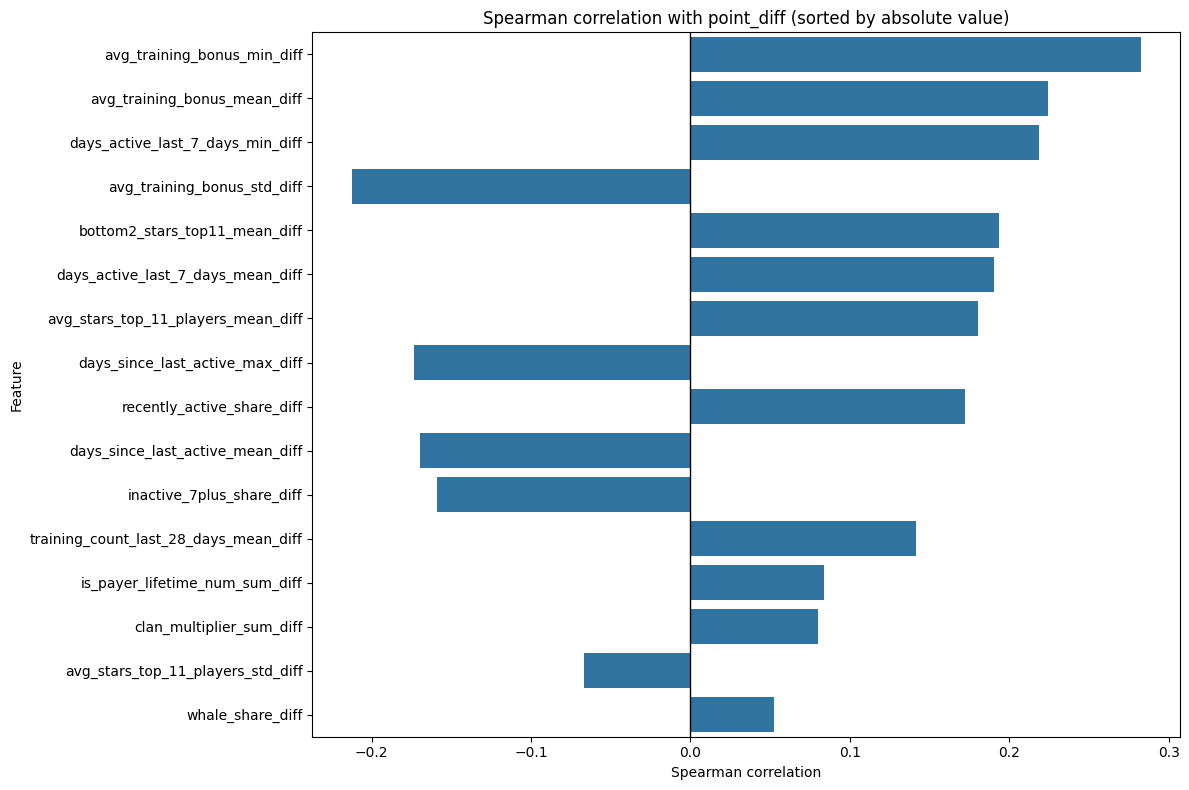

In [12]:
# %%
plt.figure(figsize=(12, max(8, 0.3 * len(diff_point_corr))))
sns.barplot(
    data=diff_point_corr,
    y="feature",
    x="spearman_corr_with_point_diff",
    orient="h"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Spearman correlation with point_diff (sorted by absolute value)")
plt.xlabel("Spearman correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Feature relationship with point margin

Instead of looking only at binary win/loss, I also compare feature differences against the final point difference. Spearman correlation is used because the relationship may not be linear, but the direction and ranking of feature gaps can still be informative.

In [13]:
matchup["point_diff"] = matchup["clan_1_points"] - matchup["clan_2_points"]

plot_df = matchup[diff_cols + ["point_diff"]].copy()

long_df = plot_df.melt(
    id_vars="point_diff",
    value_vars=diff_cols,
    var_name="feature",
    value_name="feature_value"
)

print(long_df.shape)
display(long_df.head())

(388608, 3)


,point_diff,feature,feature_value
0,-72,days_active_last_7_days_mean_diff,0.166667
1,-78,days_active_last_7_days_mean_diff,-2.000000
2,-84,days_active_last_7_days_mean_diff,1.833333
3,-84,days_active_last_7_days_mean_diff,-3.166667
4,-90,days_active_last_7_days_mean_diff,-1.666667


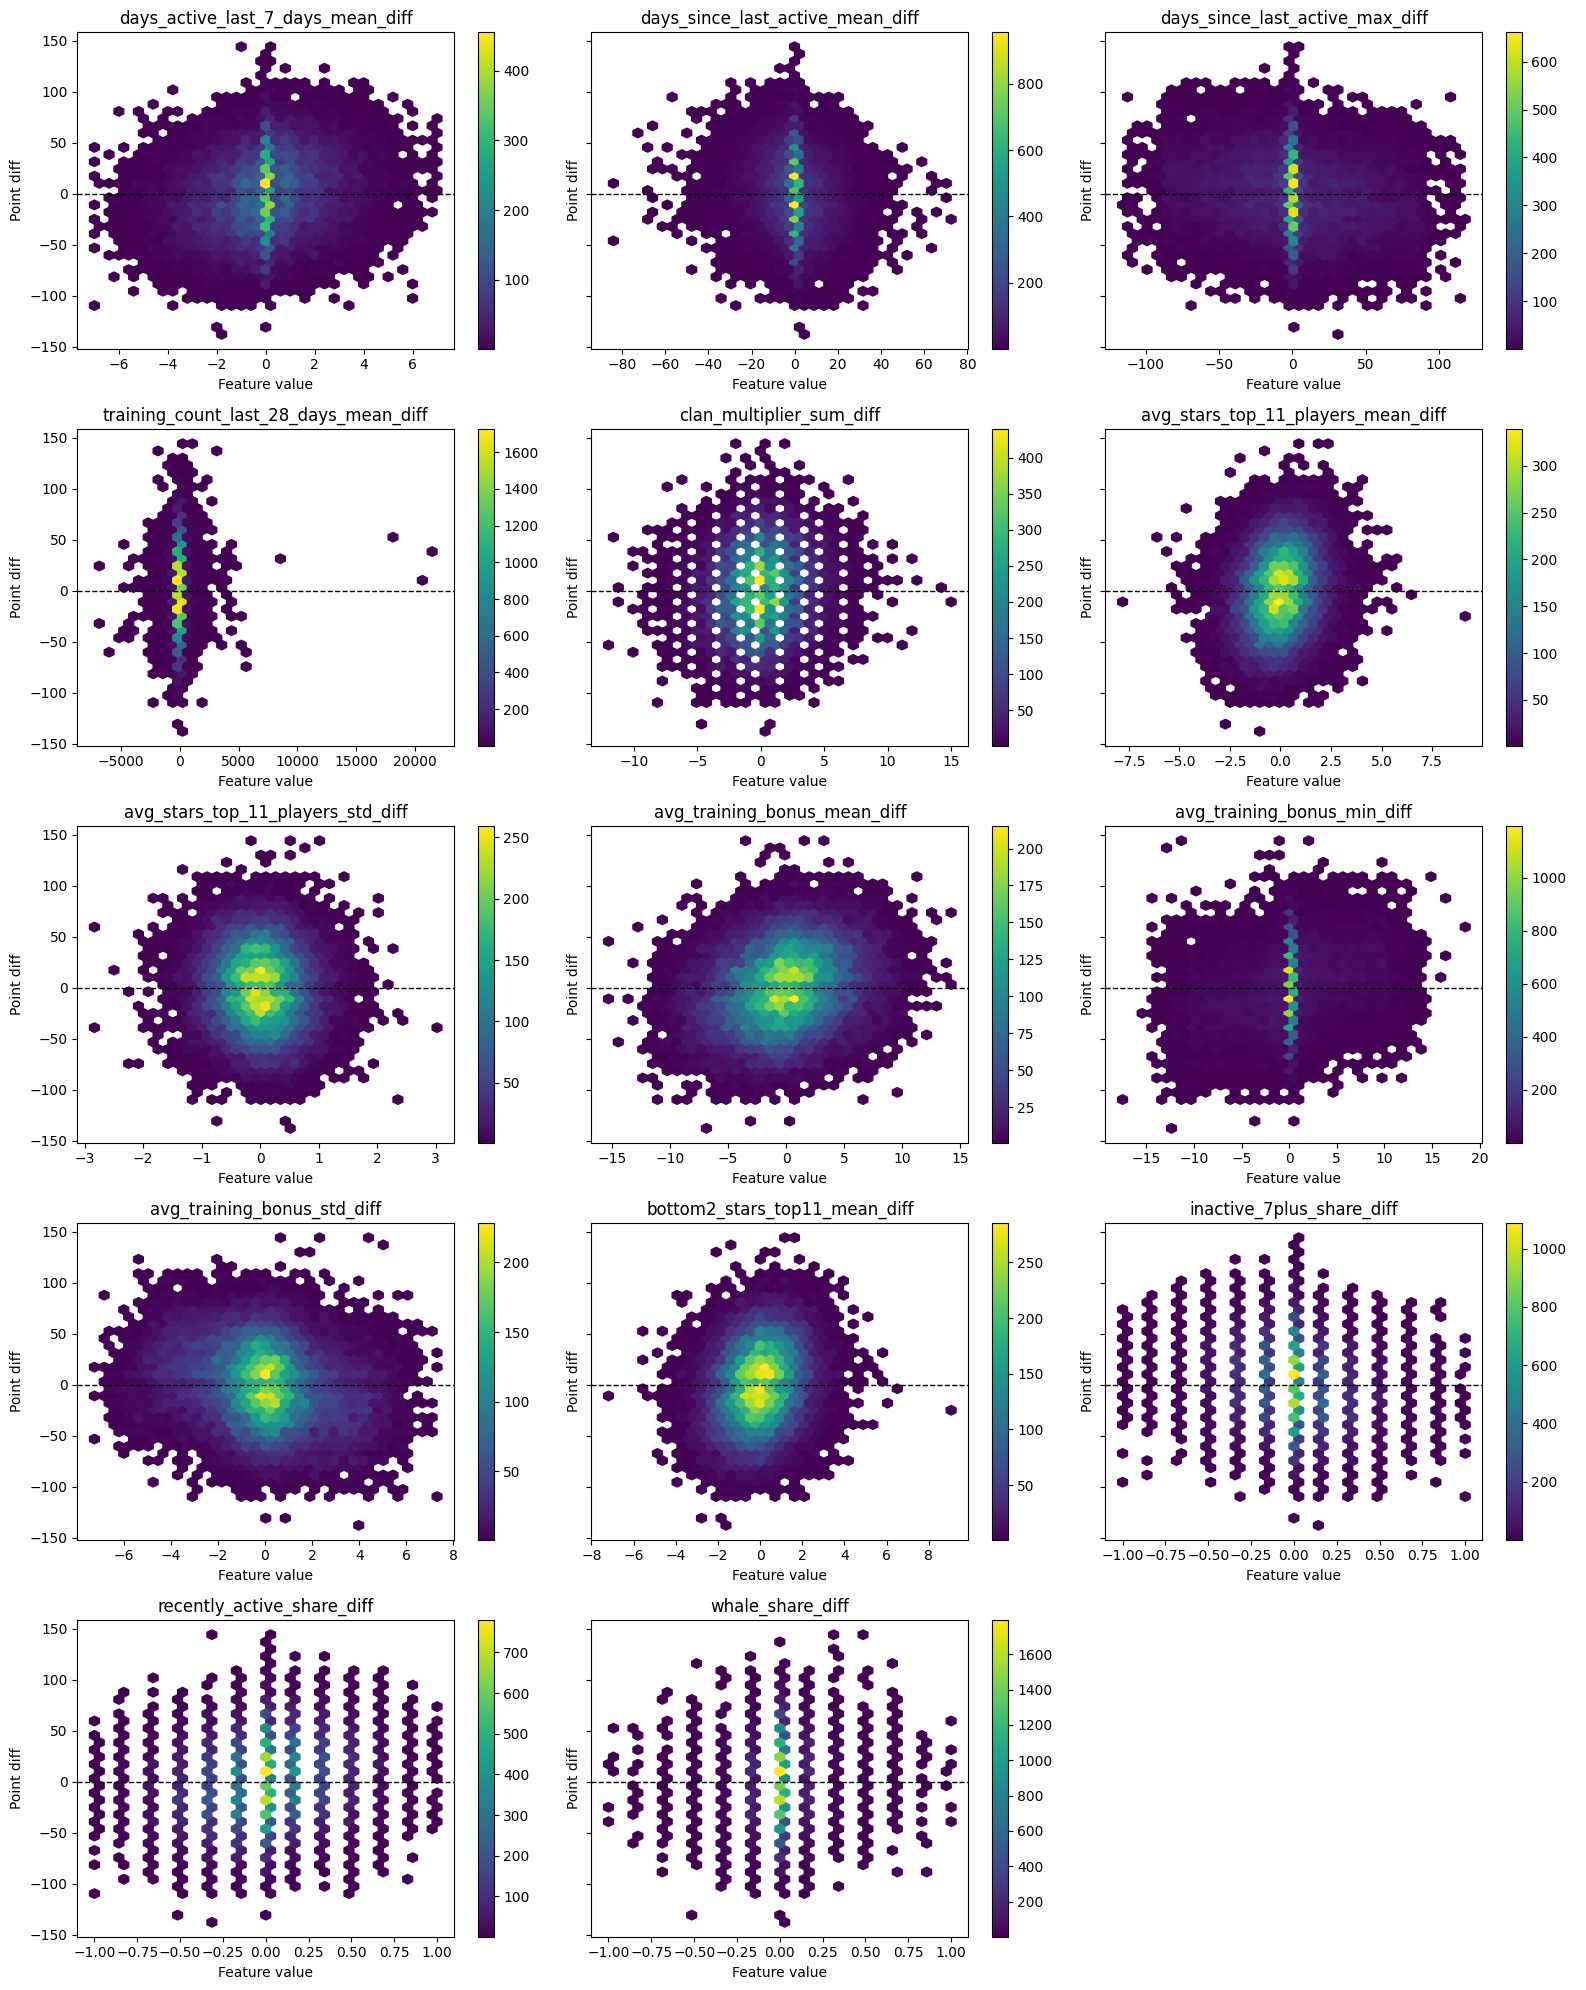

In [14]:
continuous_feats = [
    c for c in diff_cols
    if matchup[c].nunique() > 20
]

ncols = 3
nrows = int(np.ceil(len(continuous_feats) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), sharey=True)
axes = axes.flatten()

for ax, feat in zip(axes, continuous_feats):
    hb = ax.hexbin(
        matchup[feat],
        matchup["point_diff"],
        gridsize=35,
        mincnt=1
    )
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(feat)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Point diff")
    fig.colorbar(hb, ax=ax)

for ax in axes[len(continuous_feats):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

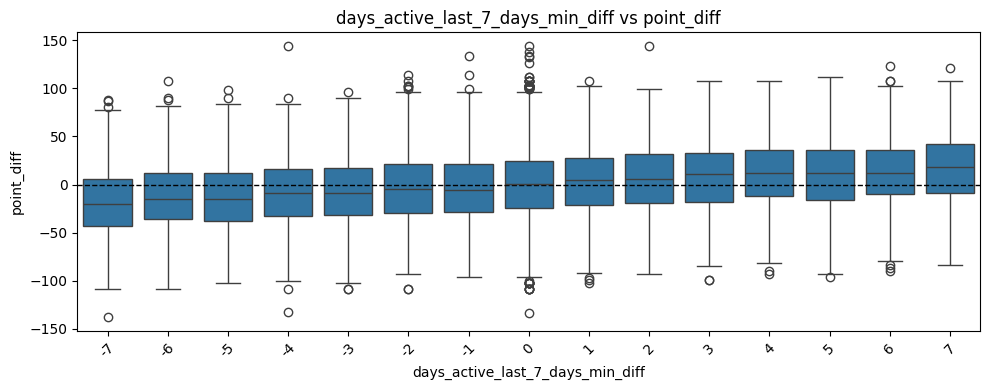

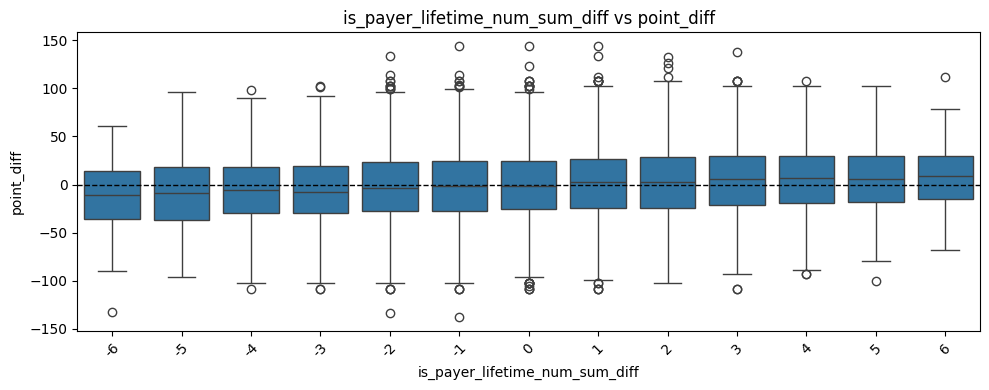

In [15]:
discrete_feats = [
    c for c in diff_cols
    if matchup[c].nunique() <= 20
]

for feat in discrete_feats:
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=matchup, x=feat, y="point_diff")
    plt.axhline(0, color="black", linestyle="--", linewidth=1)
    plt.title(f"{feat} vs point_diff")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [21]:
matchup["point_diff"] = matchup["clan_1_points"] - matchup["clan_2_points"]
matchup["abs_point_diff"] = matchup["point_diff"].abs()

margin_bucket_labels = [
    "Q1_closest",
    "Q2",
    "Q3",
    "Q4",
    "Q5_largest",
]

matchup["margin_bucket"] = pd.cut(
    matchup["abs_point_diff"],
    bins=[0, 10, 20, 31, 47, np.inf],
    labels=margin_bucket_labels,
    include_lowest=True,
)

bucket_corr_rows = []

for bucket, df_bucket in matchup.groupby("margin_bucket", observed=False):
    for col in diff_cols:
        valid = df_bucket[[col, "point_diff"]].dropna()

        if len(valid) > 1 and valid[col].nunique() > 1:
            bucket_corr_rows.append({
                "margin_bucket": bucket,
                "feature": col,
                "spearman_corr": valid[col].corr(valid["point_diff"], method="spearman"),
                "n_rows": len(valid),
            })

bucket_corr = pd.DataFrame(bucket_corr_rows)
bucket_corr["abs_corr"] = bucket_corr["spearman_corr"].abs()

bucket_corr["margin_bucket"] = pd.Categorical(
    bucket_corr["margin_bucket"],
    categories=margin_bucket_labels,
    ordered=True,
)



## Correlations by match closeness

Some matches are decided by very small margins, while others are much more decisive. I split matches by absolute point difference to check whether feature signals are stronger in large-margin matches than in close matches.

This is only an exploratory association check. A stronger correlation in a bucket does not mean the feature caused the result; it only shows that the feature gap tends to move together with the observed point margin in historical data.

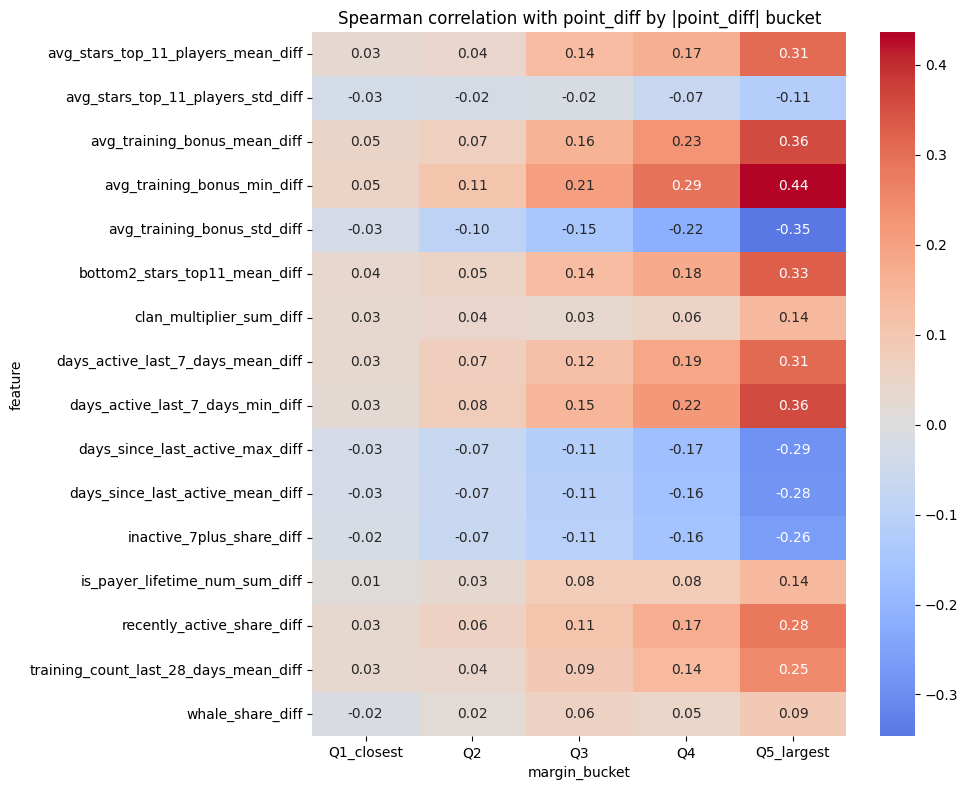

In [17]:
heatmap_df = (
    bucket_corr
    .pivot(index="feature", columns="margin_bucket", values="spearman_corr")
)

plt.figure(figsize=(10, max(8, 0.4 * len(heatmap_df))))
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Spearman correlation with point_diff by |point_diff| bucket")
plt.tight_layout()
plt.show()

## Balance and weak-link audit

This section tests whether balanced clans perform differently from top-heavy or uneven clans. I create simple imbalance features based on spread, top-vs-bottom gaps, and concentration. The goal is to see whether roster depth matters beyond average clan strength.

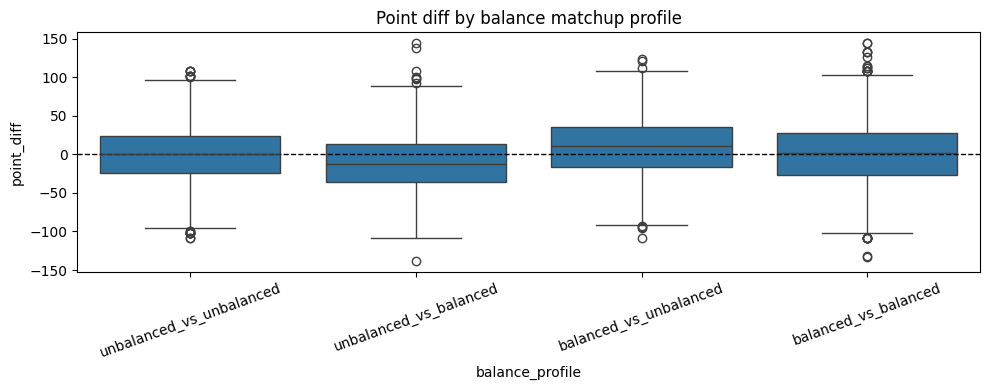

In [23]:
balance_members = members.copy()

# sort by quality so top/bottom splits are consistent
balance_members = balance_members.sort_values(
    ["clan_id", "avg_stars_top_11_players", "user_id"],
    ascending=[True, False, True]
).reset_index(drop=True)

def safe_max_share(x):
    x = np.asarray(x, dtype=float)
    total = x.sum()
    if total <= 0:
        return 0.0
    return float(x.max() / total)

balance_rows = []

for clan_id, g in balance_members.groupby("clan_id"):
    g = g.reset_index(drop=True)

    quality = g["avg_stars_top_11_players"].astype(float).to_numpy()
    bonus = g["avg_training_bonus"].astype(float).to_numpy()
    activity7 = g["days_active_last_7_days"].astype(float).to_numpy()
    multiplier = g["clan_multiplier"].astype(float).to_numpy()

    row = {"clan_id": clan_id}

    for name, arr in {
        "quality": quality,
        "bonus": bonus,
        "activity7": activity7,
        "multiplier": multiplier,
    }.items():
        row[f"{name}_std"] = arr.std(ddof=0)
        row[f"{name}_top2_minus_bottom2"] = arr[:2].mean() - arr[-2:].mean()
        row[f"{name}_max_share"] = safe_max_share(arr)

    # simple composite imbalance score
    # higher = more unbalanced
    row["imbalance_score"] = np.mean([
        row["quality_std"],
        row["quality_top2_minus_bottom2"],
        row["bonus_std"],
        row["bonus_top2_minus_bottom2"],
        row["activity7_std"],
        row["activity7_top2_minus_bottom2"],
    ])

    balance_rows.append(row)

clan_balance = pd.DataFrame(balance_rows)



# merge into matchup
balance1 = clan_balance.add_prefix("clan1_")
balance2 = clan_balance.add_prefix("clan2_")

balance_matchup = (
    matches[["clan_1_id", "clan_2_id", "clan_1_points", "clan_2_points", "clan_winner"]]
    .merge(balance1, left_on="clan_1_id", right_on="clan1_clan_id", how="left")
    .merge(balance2, left_on="clan_2_id", right_on="clan2_clan_id", how="left")
)

balance_matchup["point_diff"] = balance_matchup["clan_1_points"] - balance_matchup["clan_2_points"]
balance_matchup["target_clan1_win"] = (balance_matchup["clan_winner"] == 1).astype(int)

# oriented diffs: positive means clan1 is MORE BALANCED than clan2
balance_feats = [c for c in clan_balance.columns if c != "clan_id"]

balance_diff_cols = []

for feat in balance_feats:
    c1 = f"clan1_{feat}"
    c2 = f"clan2_{feat}"
    diff_col = f"{feat}_balance_adv"

    # smaller value = more balanced, so reverse the sign
    balance_matchup[diff_col] = balance_matchup[c2] - balance_matchup[c1]
    balance_diff_cols.append(diff_col)

# correlation with point_diff
balance_corr_rows = []

for col in balance_diff_cols:
    if balance_matchup[col].nunique() > 1:
        balance_corr_rows.append({
            "feature": col,
            "spearman_corr_with_point_diff": balance_matchup[col].corr(
                balance_matchup["point_diff"], method="spearman"
            )
        })

balance_corr = (
    pd.DataFrame(balance_corr_rows)
    .assign(abs_corr=lambda x: x["spearman_corr_with_point_diff"].abs())
    .sort_values("abs_corr", ascending=False)
    .reset_index(drop=True)
)



# classify clans as balanced / unbalanced using median split on composite imbalance
median_imb = clan_balance["imbalance_score"].median()

clan_balance["balance_label"] = np.where(
    clan_balance["imbalance_score"] <= median_imb,
    "balanced",
    "unbalanced"
)

balance_label_1 = clan_balance[["clan_id", "balance_label"]].rename(
    columns={"clan_id": "clan_1_id", "balance_label": "clan1_balance_label"}
)
balance_label_2 = clan_balance[["clan_id", "balance_label"]].rename(
    columns={"clan_id": "clan_2_id", "balance_label": "clan2_balance_label"}
)

balance_matchup = (
    balance_matchup
    .merge(balance_label_1, on="clan_1_id", how="left")
    .merge(balance_label_2, on="clan_2_id", how="left")
)

balance_matchup["balance_profile"] = (
    balance_matchup["clan1_balance_label"] + "_vs_" + balance_matchup["clan2_balance_label"]
)



plt.figure(figsize=(10, 4))
sns.boxplot(data=balance_matchup, x="balance_profile", y="point_diff")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Point diff by balance matchup profile")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()